# Analyse et modélisation — Prédiction des retards de livraison (Madagascar)

## 1. Exploration des données (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("../data/Livraisons.csv")
print(df.shape)
df.head()

(15000, 10)


,idCommande,dateCommande,datePrevue,transporteur,modeExpedition,region,categorieProduit,quantite,distanceKm,retard
0,1,2024-04-12,2024-04-14,Service Rapide,Prioritaire,Ambatondrazaka,Alimentaire,7,251.5,0
1,2,2025-03-11,2025-03-17,Trans Mahefa,Standard,Toamasina,Artisanat,9,361.9,1
2,3,2024-09-27,2024-10-03,Mada Trans,Standard,Fenerive Est,Materiel medical,4,435.4,0
3,4,2024-04-16,2024-04-22,Service Rapide,Standard,Toamasina,Vetements,2,374.2,1
4,5,2024-03-12,2024-03-18,Mami,Standard,Toamasina,Vetements,4,351.1,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   idCommande        15000 non-null  int64  
 1   dateCommande      15000 non-null  str    
 2   datePrevue        15000 non-null  str    
 3   transporteur      15000 non-null  str    
 4   modeExpedition    15000 non-null  str    
 5   region            15000 non-null  str    
 6   categorieProduit  15000 non-null  str    
 7   quantite          15000 non-null  int64  
 8   distanceKm        15000 non-null  float64
 9   retard            15000 non-null  int64  
dtypes: float64(1), int64(3), str(6)
memory usage: 1.1 MB


In [14]:
df["dateCommande"] = pd.to_datetime(df["dateCommande"])
df["datePrevue"] = pd.to_datetime(df["datePrevue"])

In [15]:
print(df.shape)
df.info()

(15000, 13)
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   idCommande        15000 non-null  int64         
 1   dateCommande      15000 non-null  datetime64[us]
 2   datePrevue        15000 non-null  datetime64[us]
 3   transporteur      15000 non-null  str           
 4   modeExpedition    15000 non-null  str           
 5   region            15000 non-null  str           
 6   categorieProduit  15000 non-null  str           
 7   quantite          15000 non-null  int64         
 8   distanceKm        15000 non-null  float64       
 9   retard            15000 non-null  int64         
 10  delaiPrevuJours   15000 non-null  int64         
 11  jourSemaine       15000 non-null  str           
 12  mois              15000 non-null  int32         
dtypes: datetime64[us](2), float64(1), int32(1), int64(4), str(5)
memory usage: 

In [16]:
df.describe()

,idCommande,dateCommande,datePrevue,quantite,distanceKm,retard,delaiPrevuJours,mois
count,15000.000000,15000,15000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,2024-12-31 17:49:03.360000,2025-01-06 16:06:48.960000,4.977467,355.611713,0.376933,5.929000,6.494800
min,1.000000,2024-01-01 00:00:00,2024-01-02 00:00:00,1.000000,0.000000,0.000000,1.000000,1.000000
25%,3750.750000,2024-07-01 00:00:00,2024-07-07 00:00:00,3.000000,13.100000,0.000000,3.000000,4.000000
50%,7500.500000,2025-01-03 00:00:00,2025-01-09 00:00:00,5.000000,353.400000,0.000000,6.000000,7.000000
75%,11250.250000,2025-07-04 00:00:00,2025-07-10 00:00:00,7.000000,563.000000,1.000000,9.000000,9.000000
max,15000.000000,2025-12-30 00:00:00,2026-01-09 00:00:00,9.000000,1127.800000,1.000000,13.000000,12.000000
std,4330.271354,NaN,NaN,2.602168,330.842303,0.484634,3.077497,3.431767


In [17]:
df.isnull().sum()

idCommande          0
dateCommande        0
datePrevue          0
transporteur        0
modeExpedition      0
region              0
categorieProduit    0
quantite            0
distanceKm          0
retard              0
delaiPrevuJours     0
jourSemaine         0
mois                0
dtype: int64

retard
0    62.306667
1    37.693333
Name: proportion, dtype: float64


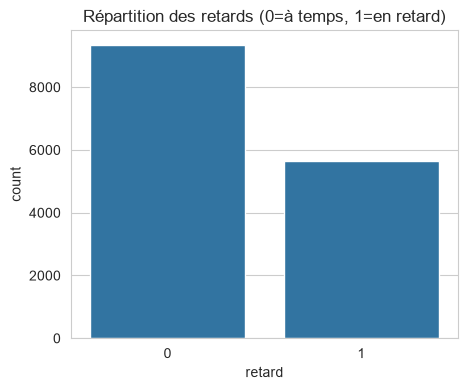

In [18]:
print(df["retard"].value_counts(normalize=True) * 100)

plt.figure(figsize=(5,4))
sns.countplot(data=df, x="retard")
plt.title("Répartition des retards (0=à temps, 1=en retard)")
plt.show()

## L'ingénierie des variables liées aux dates

In [23]:
df["dateCommande"] = pd.to_datetime(df["dateCommande"])
df["datePrevue"] = pd.to_datetime(df["datePrevue"])

df["delaiPrevuJours"] = (df["datePrevue"] - df["dateCommande"]).dt.days
df["jourSemaine"] = df["dateCommande"].dt.day_name()
df["mois"] = df["dateCommande"].dt.month

df[["dateCommande", "datePrevue", "delaiPrevuJours", "jourSemaine", "mois"]].head()

,dateCommande,datePrevue,delaiPrevuJours,jourSemaine,mois
0,2024-04-12,2024-04-14,2,Friday,4
1,2025-03-11,2025-03-17,6,Tuesday,3
2,2024-09-27,2024-10-03,6,Friday,9
3,2024-04-16,2024-04-22,6,Tuesday,4
4,2024-03-12,2024-03-18,6,Tuesday,3


transporteur
Service Rapide    0.558171
Sonatra           0.427134
Mami              0.384332
Trans Mahefa      0.313230
Mada Trans        0.264300
Name: retard, dtype: float64


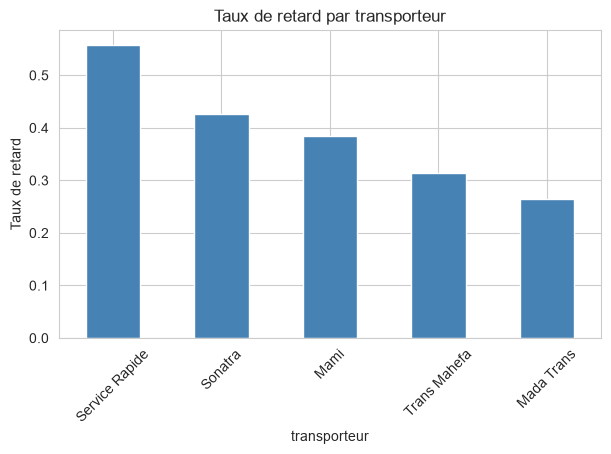

In [19]:
taux_par_transporteur = df.groupby("transporteur")["retard"].mean().sort_values(ascending=False)
print(taux_par_transporteur)

plt.figure(figsize=(7,4))
taux_par_transporteur.plot(kind="bar", color="steelblue")
plt.title("Taux de retard par transporteur")
plt.ylabel("Taux de retard")
plt.xticks(rotation=45)
plt.show()

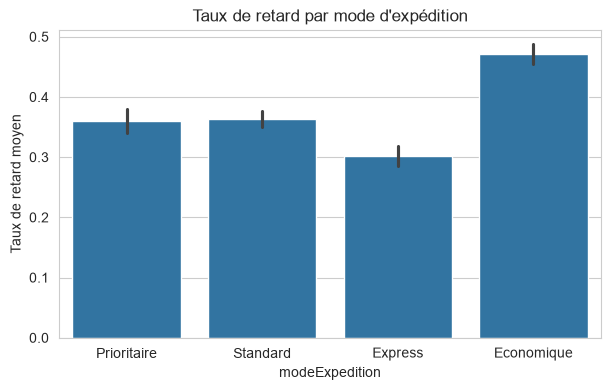

In [27]:
plt.figure(figsize=(7,4))
sns.barplot(data=df, x="modeExpedition", y="retard", estimator=np.mean)
plt.title("Taux de retard par mode d'expédition")
plt.ylabel("Taux de retard moyen")
plt.show()

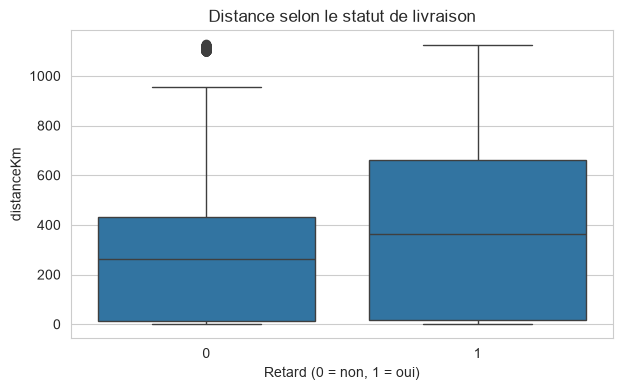

In [9]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="retard", y="distanceKm")
plt.title("Distance selon le statut de livraison")
plt.xlabel("Retard (0 = non, 1 = oui)")
plt.show()

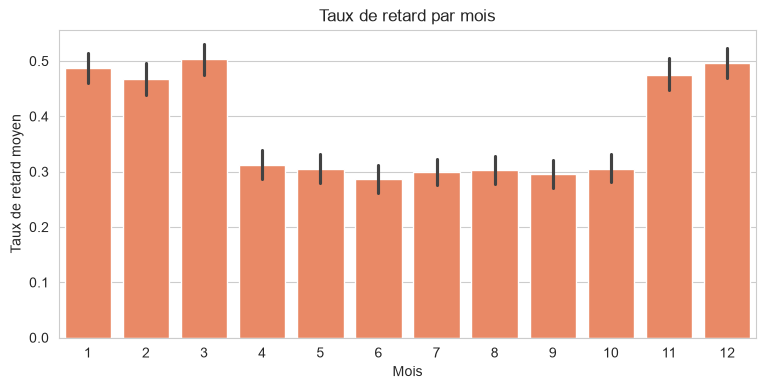

In [12]:
plt.figure(figsize=(9,4))
sns.barplot(data=df, x="mois", y="retard", estimator=np.mean, color="coral")
plt.title("Taux de retard par mois")
plt.xlabel("Mois")
plt.ylabel("Taux de retard moyen")
plt.show()

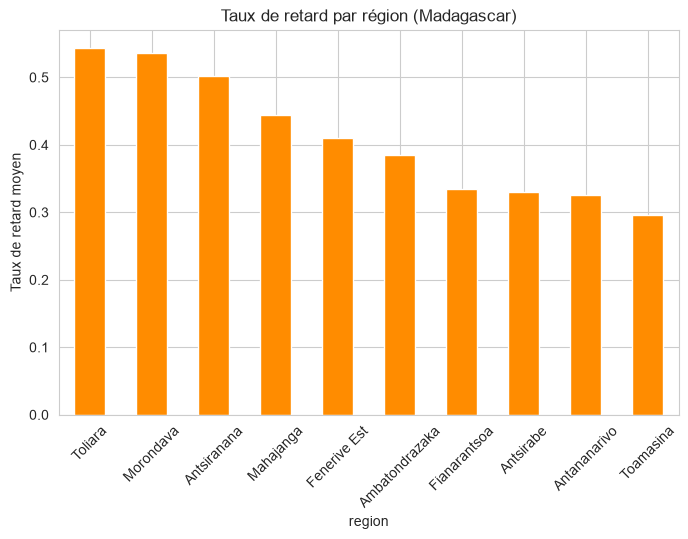

In [13]:
plt.figure(figsize=(8,5))
taux_region = df.groupby("region")["retard"].mean().sort_values(ascending=False)
taux_region.plot(kind="bar", color="darkorange")
plt.title("Taux de retard par région (Madagascar)")
plt.ylabel("Taux de retard moyen")
plt.xticks(rotation=45)
plt.show()

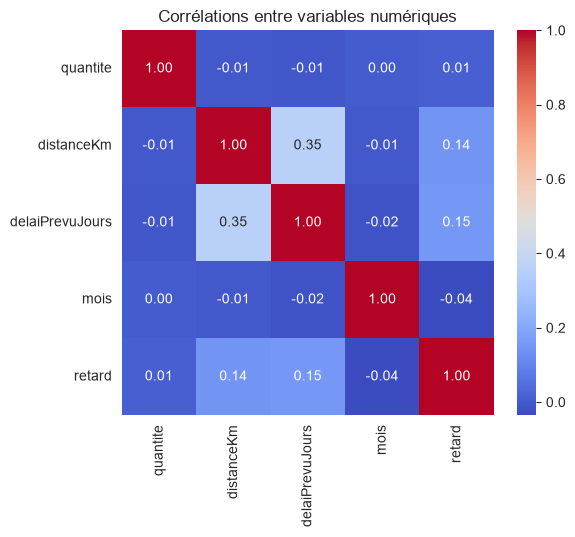

In [12]:
num_cols = ["quantite", "distanceKm", "delaiPrevuJours", "mois", "retard"]
plt.figure(figsize=(6,5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Corrélations entre variables numériques")
plt.show()

In [28]:
from sklearn.model_selection import train_test_split

# Variables explicatives
X = df[[
    "transporteur",
    "modeExpedition",
    "region",
    "categorieProduit",
    "quantite",
    "distanceKm",
    "delaiPrevuJours",
    "jourSemaine",
    "mois"
]]

# Variable cible
y = df["retard"]

# Séparation 80% entraînement / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)
print("Taille de y_train :", y_train.shape)
print("Taille de y_test  :", y_test.shape)

Taille de X_train : (12000, 9)
Taille de X_test  : (3000, 9)
Taille de y_train : (12000,)
Taille de y_test  : (3000,)


In [30]:
from sklearn.preprocessing import LabelEncoder

# Colonnes catégorielles
colonnesCategorielle = [
    "transporteur",
    "modeExpedition",
    "region",
    "categorieProduit",
    "jourSemaine"
]

# Dictionnaire pour conserver les encodeurs
encoders = {}

# Encodage de chaque colonne
for col in colonnesCategorielle:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col])
    X_test[col] = le.transform(X_test[col])
    encoders[col] = le

print("Encodage terminé.")

Encodage terminé.


## Conclusions de l'exploration

Taux de retard global : 37,69 %, contre 62,31 % de livraisons à temps.

Aucune valeur manquante n'a été détectée dans le dataset.

Les taux de retard présentent des différences importantes selon le transporteur : Service Rapide présente le taux observé le plus élevé (55,82 %), tandis que Mada Trans présente le plus faible (26,43 %).

Le mode d'expédition Économique est associé à un taux de retard plus élevé, tandis que le mode Express présente un taux plus faible.

Les régions éloignées telles que Toliara, Morondava et Antsiranana présentent des taux de retard plus élevés dans notre dataset.

Les livraisons avec une distance plus importante présentent également une tendance à avoir davantage de retards.

Une variation saisonnière du taux de retard est observée, avec des taux plus élevés principalement entre novembre et mars dans notre dataset simulé.

La corrélation montre notamment une relation modérée entre distanceKm et delaiPrevuJours (0,35), ainsi qu'une association positive de distanceKm (0,14) et delaiPrevuJours (0,15) avec retard.

Ces résultats représentent des associations observées dans un dataset simulé et ne permettent pas d'établir une relation de causalité.

## 2. Entraînement du modèle

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, precision_recall_curve, RocCurveDisplay)
import joblib
import os

In [33]:
features = [
    "transporteur", "modeExpedition", "region", "categorieProduit",
    "quantite", "distanceKm", "delaiPrevuJours", "jourSemaine", "mois"
]
target = "retard"

X = df[features].copy()
y = df[target].copy()

X.head()

,transporteur,modeExpedition,region,categorieProduit,quantite,distanceKm,delaiPrevuJours,jourSemaine,mois
0,Service Rapide,Prioritaire,Ambatondrazaka,Alimentaire,7,251.5,2,Friday,4
1,Trans Mahefa,Standard,Toamasina,Artisanat,9,361.9,6,Tuesday,3
2,Mada Trans,Standard,Fenerive Est,Materiel medical,4,435.4,6,Friday,9
3,Service Rapide,Standard,Toamasina,Vetements,2,374.2,6,Tuesday,4
4,Mami,Standard,Toamasina,Vetements,4,351.1,6,Tuesday,3


> ⚠️ **Attention au data leakage** : on exclut `id_commande` et les dates brutes
> (déjà transformées en `delai_prevu_jours`, `jour_semaine`, `mois`), ainsi que
> toute variable qui ne serait pas connue au moment de la commande.

In [34]:
colonnes_categorielles = ["transporteur", "modeExpedition", "region",
                           "categorieProduit", "jourSemaine"]

encoders = {}  # on garde les encoders pour les réutiliser dans l'API plus tard

for col in colonnes_categorielles:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    encoders[col] = le

X.head()

,transporteur,modeExpedition,region,categorieProduit,quantite,distanceKm,delaiPrevuJours,jourSemaine,mois
0,2,2,0,0,7,251.5,2,0,4
1,4,3,8,1,9,361.9,6,5,3
2,0,3,4,3,4,435.4,6,0,9
3,2,3,8,6,2,374.2,6,5,4
4,1,3,8,6,4,351.1,6,5,3


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Taux de retard (train) :", y_train.mean().round(3))
print("Taux de retard (test)  :", y_test.mean().round(3))

Train : (12000, 9) | Test : (3000, 9)
Taux de retard (train) : 0.377
Taux de retard (test)  : 0.377


In [36]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",   # gère le déséquilibre des classes
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [37]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("=== Rapport de classification ===")
print(classification_report(y_test, y_pred, target_names=["A temps", "En retard"]))

print("AUC-ROC :", round(roc_auc_score(y_test, y_proba), 3))

=== Rapport de classification ===
              precision    recall  f1-score   support

     A temps       0.75      0.66      0.70      1869
   En retard       0.53      0.63      0.58      1131

    accuracy                           0.65      3000
   macro avg       0.64      0.65      0.64      3000
weighted avg       0.67      0.65      0.66      3000

AUC-ROC : 0.704


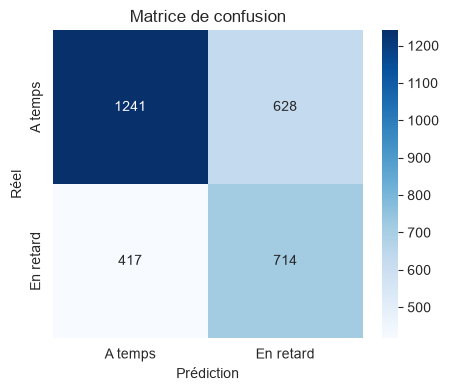

In [38]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["A temps", "En retard"],
            yticklabels=["A temps", "En retard"])
plt.xlabel("Prédiction")
plt.ylabel("Réel")
plt.title("Matrice de confusion")
plt.show()

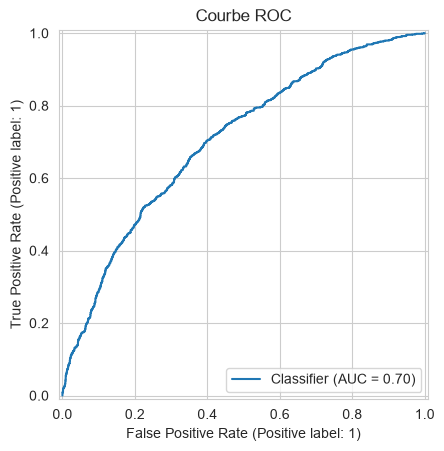

In [39]:
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("Courbe ROC")
plt.show()

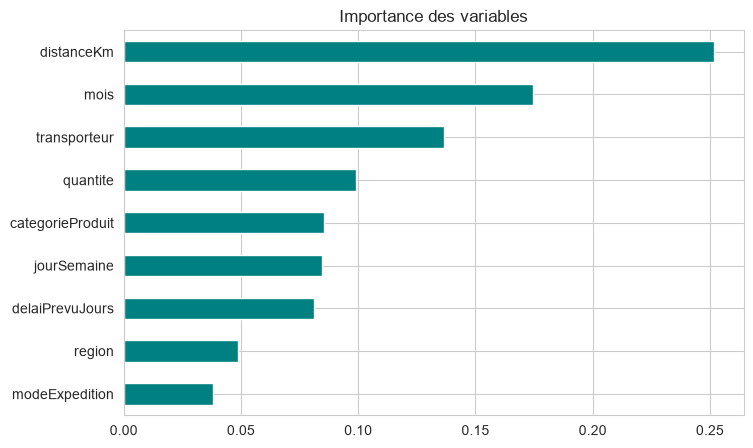

distanceKm          0.251801
mois                0.174508
transporteur        0.136725
quantite            0.098873
categorieProduit    0.085561
jourSemaine         0.084679
delaiPrevuJours     0.080956
region              0.048676
modeExpedition      0.038221
dtype: float64


In [40]:
importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(8,5))
importances.plot(kind="barh", color="teal")
plt.title("Importance des variables")
plt.gca().invert_yaxis()
plt.show()

print(importances)

In [41]:
os.makedirs("../models", exist_ok=True)

joblib.dump(model, "../models/model_retard.pkl")
joblib.dump(encoders, "../models/encoders.pkl")
joblib.dump(features, "../models/features.pkl")

print("Modèle et encoders sauvegardés dans models/")

Modèle et encoders sauvegardés dans models/


## Résultats du modèle

- Modèle : Random Forest (300 arbres, profondeur max 12)
- AUC-ROC : voir cellule d'évaluation ci-dessus (viser > 0.75 pour un bon modèle)
- Variables les plus importantes : transporteur, région, distance, délai prévu

**Prochaine étape :** créer l'API FastAPI qui charge `model_retard.pkl` et expose un endpoint `/predict`.